In [4]:
from importlib.metadata import version
import torch

print("torch version:", version("torch"))


from previous_chapters import GPTModel

GPT_CONFIG_124M = {
    "vocab_size": 50257,   # Vocabulary size
    "context_length": 256, # Shortened context length (orig: 1024)
    "emb_dim": 768,        # Embedding dimension
    "n_heads": 12,         # Number of attention heads
    "n_layers": 12,        # Number of layers
    "drop_rate": 0.1,      # Dropout rate
    "qkv_bias": False      # Query-key-value bias
}

device = torch.device("mps")

torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)
model.eval();  # Disable dropout during inference

torch version: 2.14.0


In [5]:
import os
import urllib.request

file_path = "the-verdict.txt"
url = "https://raw.githubusercontent.com/rasbt/LLMs-from-scratch/main/ch02/01_main-chapter-code/the-verdict.txt"

if not os.path.exists(file_path):
    with urllib.request.urlopen(url) as response:
        text_data = response.read().decode('utf-8')
    with open(file_path, "w", encoding="utf-8") as file:
        file.write(text_data)
else:
    with open(file_path, "r", encoding="utf-8") as file:
        text_data = file.read()

In [6]:
from previous_chapters import create_dataloader_v1

train_ratio = 0.90
split_idx = int(train_ratio * len(text_data))


torch.manual_seed(123)

train_loader = create_dataloader_v1(
    text_data[:split_idx],
    batch_size=2,
    max_length=GPT_CONFIG_124M["context_length"],
    stride=GPT_CONFIG_124M["context_length"],
    drop_last=True,
    shuffle=True,
    num_workers=0
)

val_loader = create_dataloader_v1(
    text_data[split_idx:],
    batch_size=2,
    max_length=GPT_CONFIG_124M["context_length"],
    stride=GPT_CONFIG_124M["context_length"],
    drop_last=False,
    shuffle=False,
    num_workers=0
)

In [10]:
n_epochs = 15
initial_lr = 0.0001
peak_lr = 0.01

In [12]:
total_steps = len(train_loader) * n_epochs
warmup_steps = int(0.2 * total_steps)
print(warmup_steps)

27


In [16]:
lr_increment = (peak_lr - initial_lr) / warmup_steps

global_step = -1
track_lrs = []

optimizer = torch.optim.AdamW(model.parameters(), weight_decay=0.1)

for epoch in range(n_epochs):
    for input_batch, target_batch in train_loader:
        optimizer.zero_grad()
        global_step += 1
    
        if global_step < warmup_steps:
            lr = initial_lr + global_step * lr_increment
        else:
            lr = peak_lr

        for param_group in optimizer.param_groups:
            param_group["lr"] = lr
        #训练过是已经省略了
        track_lrs.append(optimizer.param_groups[0]["lr"])

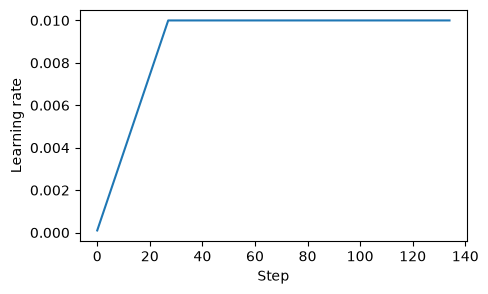

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize = (5,3))
plt.ylabel('Learning rate')
plt.xlabel('Step')
total_training_steps = len(train_loader) * n_epochs
plt.plot(range(total_training_steps),track_lrs)
plt.show()

In [19]:
import math

min_lr = 0.1 * initial_lr
track_lrs = []

lr_increment = (peak_lr - initial_lr) / warmup_steps
global_step = -1

for epoch in range(n_epochs):
    for input_batch, target_batch in train_loader:
        optimizer.zero_grad()
        global_step += 1
    
        if global_step < warmup_steps:
            lr = initial_lr + global_step * lr_increment  
        else:
            progress = ((global_step - warmup_steps) / 
                        (total_training_steps - warmup_steps))
            #*0.5是为了归一化
            lr = min_lr + (peak_lr - min_lr) * 0.5 * (
                1 + math.cos(math.pi * progress))
        
        for param_group in optimizer.param_groups:
            param_group["lr"] = lr
        track_lrs.append(optimizer.param_groups[0]["lr"])

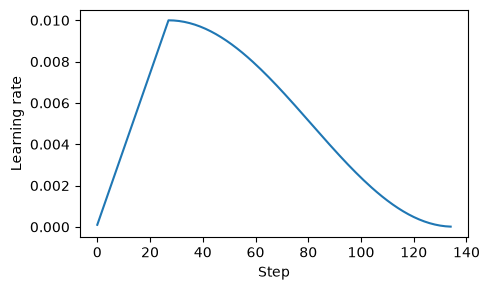

In [20]:
plt.figure(figsize=(5, 3))
plt.ylabel("Learning rate")
plt.xlabel("Step")
plt.plot(range(total_training_steps), track_lrs)
plt.tight_layout(); plt.savefig("2.pdf")
plt.show()

In [21]:
from previous_chapters import calc_loss_batch

torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)
model.to(device)

loss = calc_loss_batch(input_batch, target_batch, model, device)
loss.backward()

In [22]:
def find_highest_gradient(model):
    max_grad = None
    for param in model.parameters():
        if param.grad is not None:
            grad_values = param.grad.data.flatten()
            max_grad_param = grad_values.max()
            if max_grad is None or max_grad_param > max_grad:
                max_grad = max_grad_param

    return max_grad

#grad是单一权重的偏导数,不是梯度的范数
print(find_highest_gradient(model))

tensor(0.0549, device='mps:0')


In [23]:
torch.nn.utils.clip_grad_norm_(model.parameters(),max_norm = 1.0)

tensor(2.2110, device='mps:0')

In [24]:
#偏导数组成的梯度的范数被限制,导致偏导数变小了
print(find_highest_gradient(model))

tensor(0.0249, device='mps:0')


In [25]:
from previous_chapters import evaluate_model,generate_and_print_sample

In [31]:
def train_model(model,train_loader,val_loader,optimizer,device,
                n_epochs,eval_freq,eval_iter,start_context,tokenizer,
                warmup_steps,initial_lr = 3e-05,min_lr = 1e-6):

    train_losses,val_losses,track_tokens_seen,track_lrs = [],[],[],[]
    tokens_seen,global_step = 0,-1

    peak_lr = optimizer.param_groups[0]['lr']

    total_training_steps = len(train_loader) * n_epochs

    lr_increment = (peak_lr - initial_lr) / warmup_steps

    for epoch in range(n_epochs):
        model.train()
        for input_batch,target_batch in train_loader:
            optimizer.zero_grad()
            global_step += 1

            if global_step < warmup_steps:
                lr = initial_lr + global_step * lr_increment
            else:
                progress = ((global_step - warmup_steps) / 
                            (total_training_steps - warmup_steps))
                lr = min_lr + (peak_lr - min_lr) * 0.5 * (1 + math.cos(math.pi * progress))

            for param_group in optimizer.param_groups:
                param_group['lr'] = lr
            track_lrs.append(lr)

            loss = calc_loss_batch(input_batch,target_batch,model,device)
            loss.backward()

            if global_step > warmup_steps:
                #梯度裁剪
                torch.nn.utils.clip_grad_norm_(model.parameters(),max_norm = 1.0)

            optimizer.step()
            #统计看过的元素总数
            tokens_seen += input_batch.numel()

            if global_step % eval_freq == 0:
                train_loss , val_loss = evaluate_model(
                    model,train_loader,val_loader,
                    device,eval_iter
                )
                train_losses.append(train_loss)
                val_losses.append(val_loss)
                track_tokens_seen.append(tokens_seen)
                print(f"Ep {epoch+1} (Iter {global_step:06d}): "
                      f"Train loss {train_loss:.3f}, "
                      f"Val loss {val_loss:.3f}"
                )

        generate_and_print_sample(
            model,tokenizer,device,start_context
        )

    return train_losses,val_losses,track_tokens_seen,track_lrs

In [32]:
import tiktoken

torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)
model.to(device)

optimizer = torch.optim.AdamW(model.parameters(), weight_decay=0.1)
tokenizer = tiktoken.get_encoding("gpt2")

n_epochs = 15
train_losses, val_losses, tokens_seen, lrs = train_model(
    model, train_loader, val_loader, optimizer, device, n_epochs=n_epochs,
    eval_freq=5, eval_iter=1, start_context="Every effort moves you",
    tokenizer=tokenizer, warmup_steps=warmup_steps, 
    initial_lr=1e-5, min_lr=1e-5
)

Ep 1 (Iter 000000): Train loss 10.969, Val loss 10.938
Ep 1 (Iter 000005): Train loss 9.336, Val loss 9.459
Every effort moves you,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Ep 2 (Iter 000010): Train loss 7.820, Val loss 8.184
Ep 2 (Iter 000015): Train loss 6.341, Val loss 6.890
Every effort moves you,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Ep 3 (Iter 000020): Train loss 6.078, Val loss 6.593
Ep 3 (Iter 000025): Train loss 5.667, Val loss 6.777
Every effort moves you, the of the of the of the of the of the of the of the of the of the of the of the of the of the of the of the of the of the of the of the of the of the of the of the, the
Ep 4 (Iter 000030): Train loss 5.738, Val loss 6.827
Ep 4 (Iter 000035): Train loss 5.808, Val loss 6.838
Every effort moves you, theis, theis, theis, theis ais.                                   
Ep 5 (Iter 000040): Train loss 5.247, Val loss 6.564
Every effort moves you, and a, and a, and a a a a a, and a a, and a, and a, and a, and a a

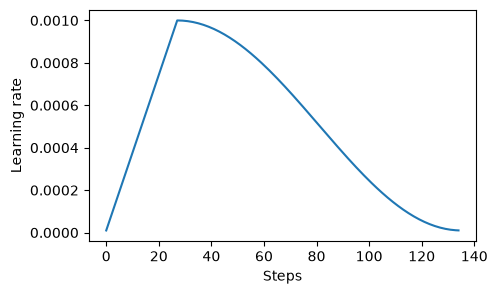

In [33]:
plt.figure(figsize=(5, 3))
plt.plot(range(len(lrs)), lrs)
plt.ylabel("Learning rate")
plt.xlabel("Steps")
plt.show()

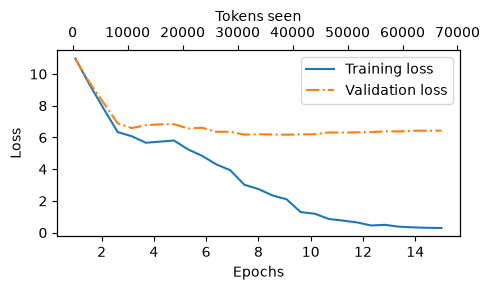

In [36]:
from previous_chapters import plot_losses

epochs_tensor = torch.linspace(1, n_epochs, len(train_losses))
plot_losses(epochs_tensor, tokens_seen, train_losses, val_losses)
plt.tight_layout()
plt.savefig("3.pdf")
plt.show()